In [7]:
import pandas as pd

In [8]:
import numpy as np

In [9]:
import matplotlib.pyplot as plt

In [10]:
import seaborn as sn

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

In [13]:
train_df.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [14]:
test_df.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,...,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,...,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,...,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,...,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,...,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False


In [15]:
train_df.shape

(699960, 26)

In [16]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-nul

In [17]:
train_df.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191548,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


In [18]:
target = 'is_fraud'

In [19]:
print(train_df[target].value_counts())
print(train_df[target].mean())

is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64
0.016699525687182123


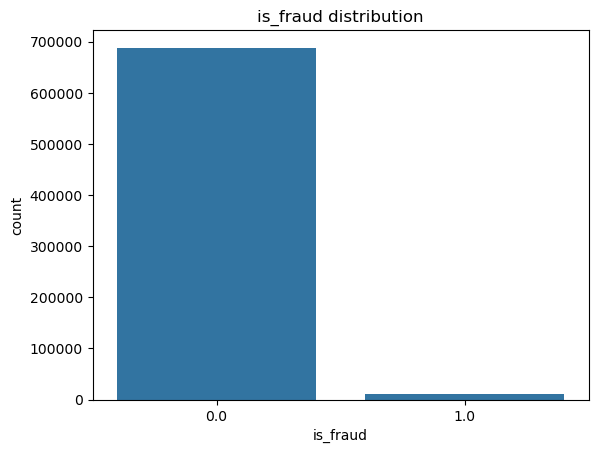

In [20]:
sn.countplot(x=train_df[target])
plt.title('is_fraud distribution')
plt.savefig('is_fraud distribution.png')
plt.show()

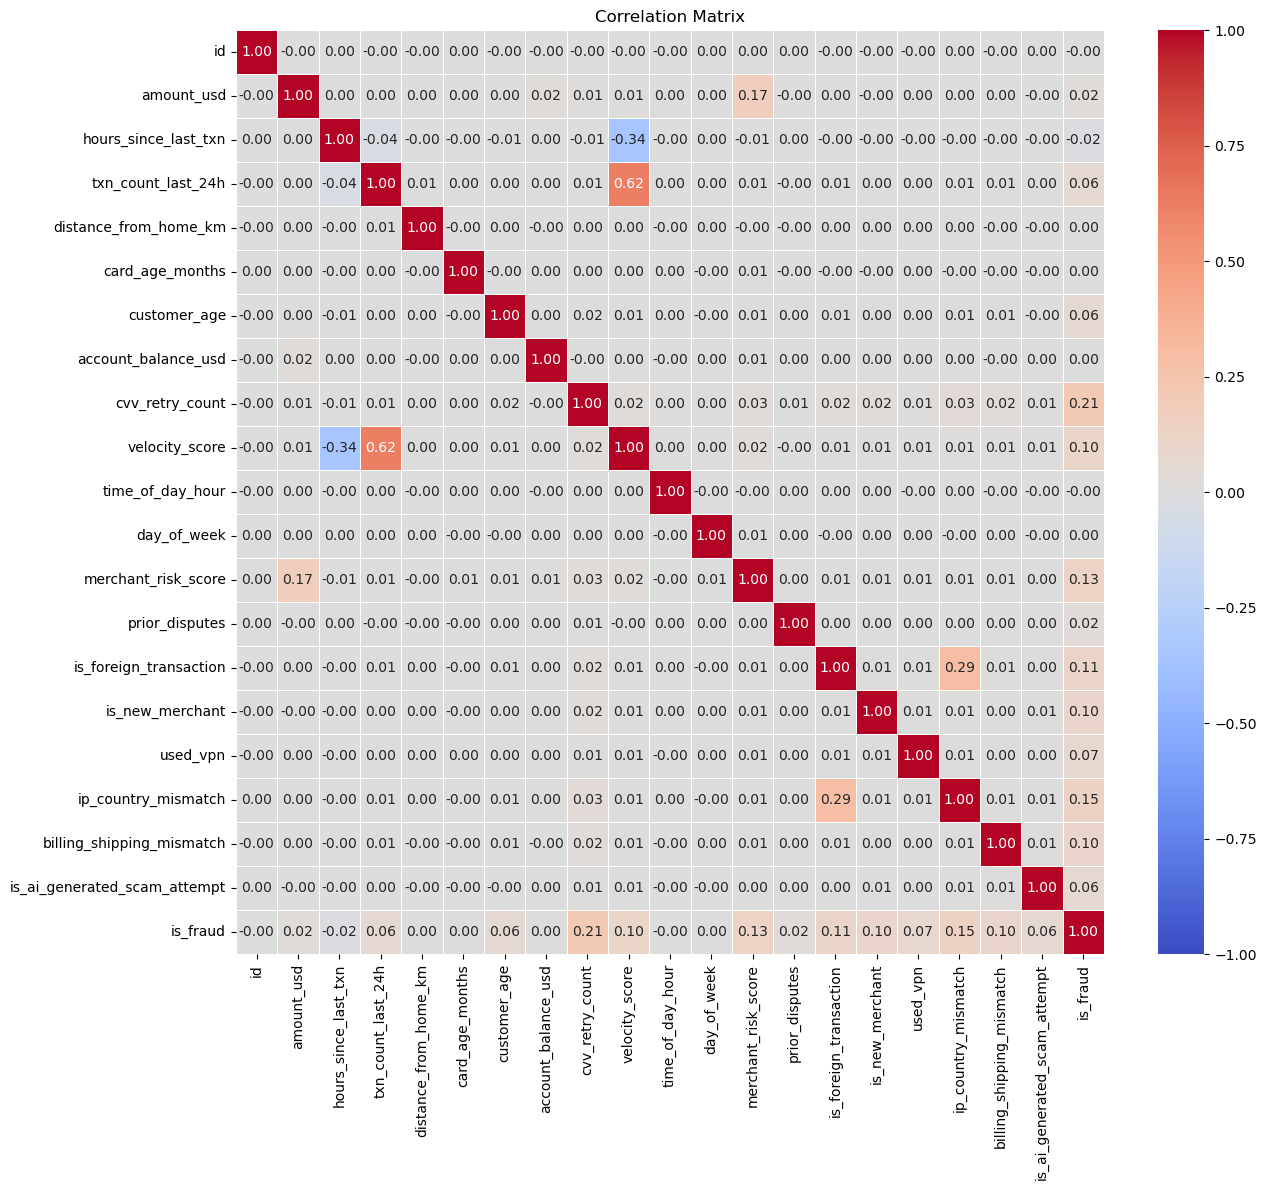

In [44]:
plt.figure(figsize=(14, 12))
sn.heatmap(train_df.corr(numeric_only=True), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.savefig("correlation_matrix.png")
plt.show()

In [21]:
bool_cols = train_df.select_dtypes(include=['bool']).columns.tolist()
train_df[bool_cols] = train_df[bool_cols].astype(int)
test_df[bool_cols] = test_df[bool_cols].astype(int)
bool_cols

['is_foreign_transaction',
 'is_new_merchant',
 'used_vpn',
 'ip_country_mismatch',
 'billing_shipping_mismatch',
 'is_ai_generated_scam_attempt']

In [22]:
x = train_df.drop(columns=[target, 'id'])
y = train_df[target]

In [23]:
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [24]:
print(len(x_train), len(x_val), len(y_train), len(y_val))

559968 139992 559968 139992


In [25]:
numerical_features = x_train.select_dtypes(include=['number']).columns.tolist()

In [26]:
nominal_features = x_train.select_dtypes(exclude=['number']).columns.tolist()

In [27]:
print(numerical_features)
print(nominal_features)

['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier

In [29]:
num_trans = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [30]:
nom_trans = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

In [31]:
preprocessor = ColumnTransformer(transformers=[
    ("numerical_features", num_trans, numerical_features),
    ("nominal_features", nom_trans, nominal_features)
])

In [32]:
clf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model_classifier", HistGradientBoostingClassifier(
        max_iter=500, learning_rate=0.05, max_depth=6,
        early_stopping=True, random_state=42))
])

In [33]:
from sklearn.metrics import roc_auc_score

In [38]:
clf.fit(x_train, y_train)
val_pred = clf.predict_proba(x_val)[:, 1]
print("Validation ROC AUC:", roc_auc_score(y_val, val_pred))

Validation ROC AUC: 0.9436888745107851


In [39]:
clf.fit(x, y)

,steps,"[('preprocessor', ...), ('model_classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical_features', ...), ('nominal_features', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [40]:
test_pred = clf.predict_proba(test_df.drop(columns=['id']))[:, 1]

In [41]:
submission = pd.DataFrame({"id": test_df["id"], "is_fraud": test_pred})
submission.to_csv("submission.csv", index=False)
print(submission.shape)
submission.head()

(299984, 2)


,id,is_fraud
0,699960,0.000332
1,699961,0.000168
2,699962,0.066290
3,699963,0.001614
4,699964,0.001608
